# NB4 — Planificación con el VLM

El VLM (LFM2.5-VL-1.6B Q4_K_M en Ollama, en la misma GPU que Unreal) aparece en tres lugares del diseño. Este cuaderno explica los tres con el código y los datos de la v4:

| Componente | Dónde | Qué decide | Estado en la v4 |
|---|---|---|---|
| **Plan de ruta sobre el mapa cenital** (§1–§8) | `src/planning/route_planner.py`, antes del despegue | Por qué calles rodear cada tramo del manifiesto | **Activo** en los lotes D, E y F, común a las cuatro celdas |
| **Capa estratégica** (§9) | `src/agents/vlm_strategic.py`, lazo lento en vuelo | Sub-metas a 15 m ancladas a la pose del fotograma | Corre con la **profundidad estimada** como fuente: el VLM no pasó el banco (NB5) |
| **Barrido en deadlock** (§10) | `src/agents/deep_scan.py` | Qué rumbo del barrido panorámico es transitable | Ídem: el juez es la profundidad |

La geometría que convierte una respuesta en una sub-meta es la misma para el VLM y para la profundidad (`depth_client.py` devuelve las mismas estructuras que el VLM). Por eso §9 vale para las dos fuentes.

**Cómo ejecutar:** no hace falta Ollama. El plan que voló el lote 6 está guardado (`route_plan/plan.json`, con la respuesta del modelo para cada parche) y el cuaderno lo **reproduce** a partir de esas respuestas. Para hacer una consulta real al modelo, poner `CONSULTA_EN_VIVO = True` en §0 con Ollama corriendo (`startOllama.ps1`).

## §0 — Configuración

In [1]:
import os, sys, json, math, glob, copy
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cv2
from IPython.display import display, Markdown

ROOT = Path.cwd().resolve()
while not (ROOT / 'config' / '.env').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
LOOP = ROOT / 'airsim-loop'
sys.path.insert(0, str(LOOP))

from src.planning import route_planner as RP
from src.planning.vlm_logprobs import choice_probs_at, value_offsets
from src.agents import vlm_strategic as VS
from src.agents import subgoal as SG

V4 = ROOT / 'airsim-runs' / 'produccion' / 'v4'
ESC = 'citysim_pilot'
PLAN_DIR = V4 / 'lote6_citysim_pilot' / ESC / 'route_plan'
BENCH = ROOT / 'airsim-runs' / 'test' / 'vlm_bench' / 'v2'
CONSULTA_EN_VIVO = False   # True: una consulta real a Ollama en §7

manifest = json.loads((ROOT / 'airsim-plan' / 'missions' / 'flightplans' / f'{ESC}.json').read_text(encoding='utf-8'))
plan = json.loads((PLAN_DIR / 'plan.json').read_text(encoding='utf-8'))
planned = json.loads((PLAN_DIR / f'{ESC}.json').read_text(encoding='utf-8'))
mv = RP.MapView.load(manifest['map'])
plt.rcParams['figure.dpi'] = 110
%config InlineBackend.figure_formats = ['jpeg']  # figuras con fotos del mapa: JPEG pesa ~10 veces menos que PNG
print(f"mapa {mv.name}: {mv.w}x{mv.h} px, {mv.scale} px/m, origen NED en el centro -> {mv.w / mv.scale:.0f} x {mv.h / mv.scale:.0f} m")
print(f"plan guardado: modelo {plan['model']}, juicio '{plan['judge']}', clave {plan['key']}, {plan['elapsed_s']} s, {len(plan['legs'])} tramos")

mapa citysim_ortho.png: 3280x3840 px, 2.0 px/m, origen NED en el centro -> 1640 x 1920 m
plan guardado: modelo lfm2.5-vl-1.6b:q4km-ctx8k, juicio 'patches', clave ad4dd01a2281, 122.3 s, 8 tramos


In [2]:
def recorte(xs, ys, margen=30):
    # Recorte del mapa registrado (RGB) y su extent en NED: este (y) horizontal, norte (x) vertical.
    x0, x1, y0, y1 = min(xs) - margen, max(xs) + margen, min(ys) - margen, max(ys) + margen
    u0, v0 = mv.to_px(x1, y0); u1, v1 = mv.to_px(x0, y1)
    u0, v0, u1, v1 = (int(max(0, round(a))) for a in (u0, v0, u1, v1))
    return cv2.cvtColor(mv.image[v0:v1, u0:u1], cv2.COLOR_BGR2RGB), [y0, y1, x0, x1]

def pts_xy(points):
    return [p[0] for p in points], [p[1] for p in points]

## §1 — El problema: la recta entre waypoints cruza manzanas

El manifiesto de misión une los waypoints en línea recta. En CitySim varias de esas rectas pasan por encima de edificios. En vuelo, la cámara a 10 m de altura ve solo la fachada que tiene delante y no sabe dónde termina. Desde arriba, en cambio, la pregunta «¿esta ruta va por la calle?» es de **reconocimiento**, el tipo de juicio que un VLM pequeño resuelve mejor que estimar distancias en primera persona.

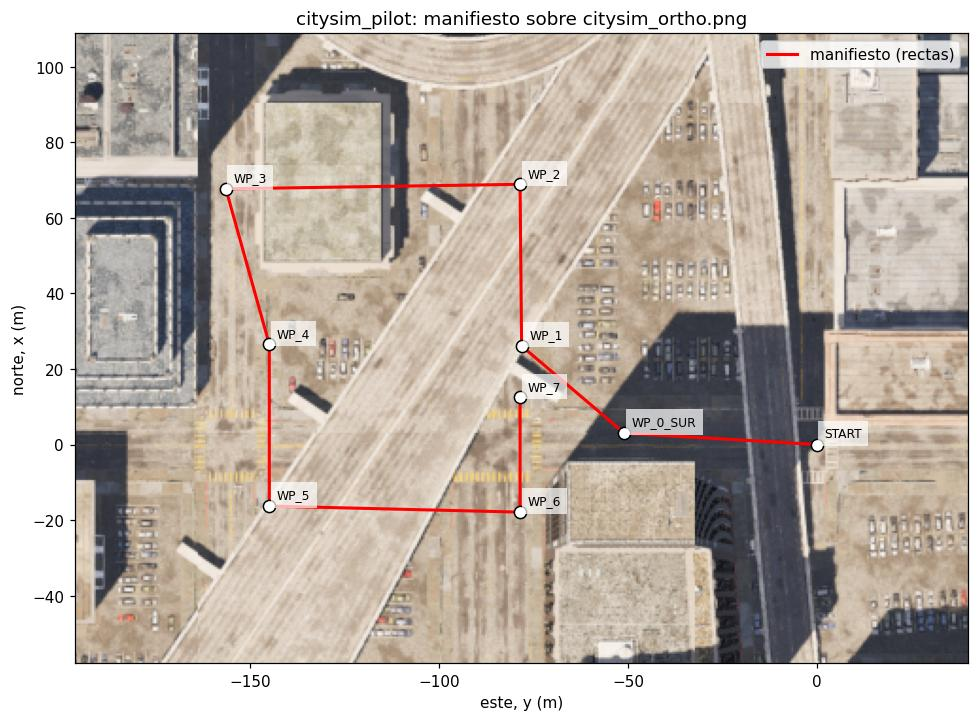

In [3]:
seq = [{'x': manifest['start_pose']['x'], 'y': manifest['start_pose']['y'], 'label': 'START'}] + manifest['waypoints']
img, ext = recorte([w['x'] for w in seq], [w['y'] for w in seq], 40)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(img, extent=ext)
ax.plot([w['y'] for w in seq], [w['x'] for w in seq], 'r-', lw=2, label='manifiesto (rectas)')
for w in seq:
    ax.plot(w['y'], w['x'], 'o', mfc='white', mec='k', ms=8)
    ax.annotate(w['label'], (w['y'], w['x']), xytext=(5, 5), textcoords='offset points', fontsize=8, bbox=dict(fc='white', alpha=.7, lw=0))
ax.set_xlabel('este, y (m)'); ax.set_ylabel('norte, x (m)'); ax.legend(); ax.set_title(f'{ESC}: manifiesto sobre {mv.name}')
plt.tight_layout(); plt.show()

## §2 — Mapa registrado

El plan solo tiene sentido si el mapa coincide con el mundo de vuelo. `citysim_ortho.png` se construyó con el propio simulador: tomas cenitales casi ortográficas desde 1000 m, pegadas a 2 px/m (informe §4.3.2). La transformación de NED a píxel es:

$$u = \tfrac{W}{2} + (y - y_0)\,s, \qquad v = \tfrac{H}{2} - (x - x_0)\,s$$

con el norte (+x) hacia arriba, el este (+y) a la derecha y $s$ en px/m (`map_scales.json`).

In [4]:
for nombre, (x, y) in {'origen': (0, 0), '20 m al norte': (20, 0), '20 m al este': (0, 20), 'WP_2': (seq[3]['x'], seq[3]['y'])}.items():
    u, v = mv.to_px(x, y)
    print(f'{nombre:<14} NED ({x:7.1f}, {y:7.1f}) -> pixel ({u:7.1f}, {v:7.1f})')

origen         NED (    0.0,     0.0) -> pixel ( 1640.0,  1920.0)
20 m al norte  NED (   20.0,     0.0) -> pixel ( 1640.0,  1880.0)
20 m al este   NED (    0.0,    20.0) -> pixel ( 1680.0,  1920.0)
WP_2           NED (   68.9,   -78.6) -> pixel ( 1482.8,  1782.2)


## §3 — Candidatas geométricas por tramo

Para cada tramo A → B, `leg_candidates()` genera rutas **sin mirar el mapa**: la recta, las dos en L (primero norte-sur o primero este-oeste, si ambos catetos superan `ROUTE_MIN_SIDE_M`) y desvíos paralelos a ±25 y ±50 m (`ROUTE_DETOURS_M`). El modelo no inventa rutas: solo las evalúa. El tramo WP_2 → WP_3 es el que la recta resuelve peor.

,candidata,vertices,longitud (m)
0,directo,2,77.9
1,desvio_izq_25m,4,127.9
2,desvio_der_25m,4,127.9
3,desvio_izq_50m,4,177.9
4,desvio_der_50m,4,177.9


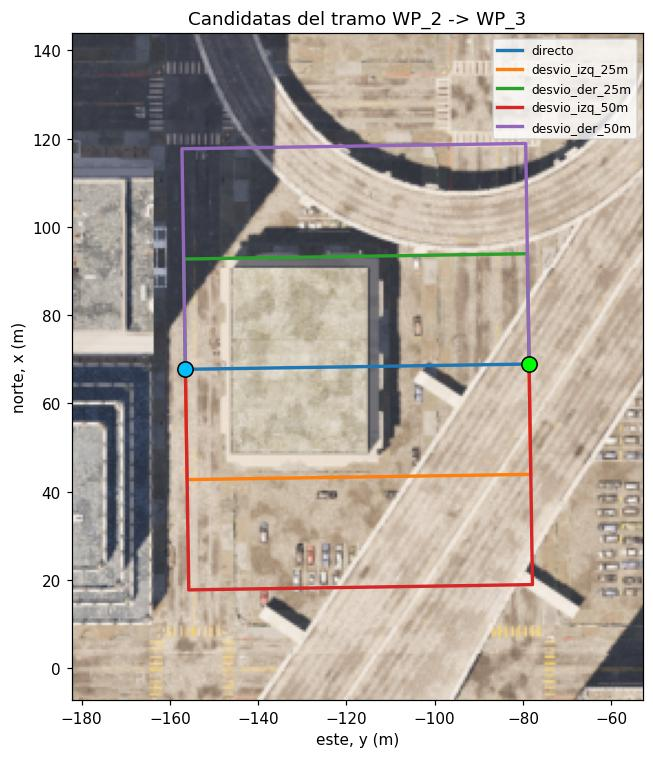

In [5]:
legs = RP.legs(manifest)
LEG = next(i for i, (a, b) in enumerate(legs) if b['label'] == 'WP_3')
a, b = legs[LEG]
cands = RP.leg_candidates((a['x'], a['y']), (b['x'], b['y']))
display(pd.DataFrame([{'candidata': c['name'], 'vertices': len(c['points']), 'longitud (m)': c['length_m']} for c in cands]))
allx = [p[0] for c in cands for p in c['points']]; ally = [p[1] for c in cands for p in c['points']]
img, ext = recorte(allx, ally, 25)
fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(img, extent=ext)
for c, col in zip(cands, plt.cm.tab10.colors):
    xs, ys = pts_xy(c['points'])
    ax.plot(ys, xs, '-', lw=2.2, color=col, label=c['name'])
ax.plot(a['y'], a['x'], 'o', ms=10, mfc='lime', mec='k'); ax.plot(b['y'], b['x'], 'o', ms=10, mfc='deepskyblue', mec='k')
ax.legend(fontsize=8); ax.set_title(f"Candidatas del tramo {a['label']} -> {b['label']}")
ax.set_xlabel('este, y (m)'); ax.set_ylabel('norte, x (m)')
plt.tight_layout(); plt.show()

## §4 — Por qué el juicio es por parches

La primera versión le mostraba al modelo la ruta entera, como pasillo o como línea (`ROUTE_JUDGE=image`), y le preguntaba sí o no. El banco (NB5) mostró que la respuesta dependía de la **forma de la pregunta** y no de la imagen. Con la línea, un modelo rechazó las 37 candidatas y el otro aprobó todas. Con el pasillo, ambos aprobaron todas. Con la pregunta invertida, ambos dijeron que todas cruzaban techos.

Abajo, lo que veía el modelo con `image` para dos candidatas. La versión vigente le pide algo más simple: **clasificar un parche** del mapa en cinco clases. Cada candidata se muestrea cada `ROUTE_PATCH_STEP_M` = 8 m. En cada punto se recorta un contexto de 48 m con un cuadrado rojo de 16 m en el centro.

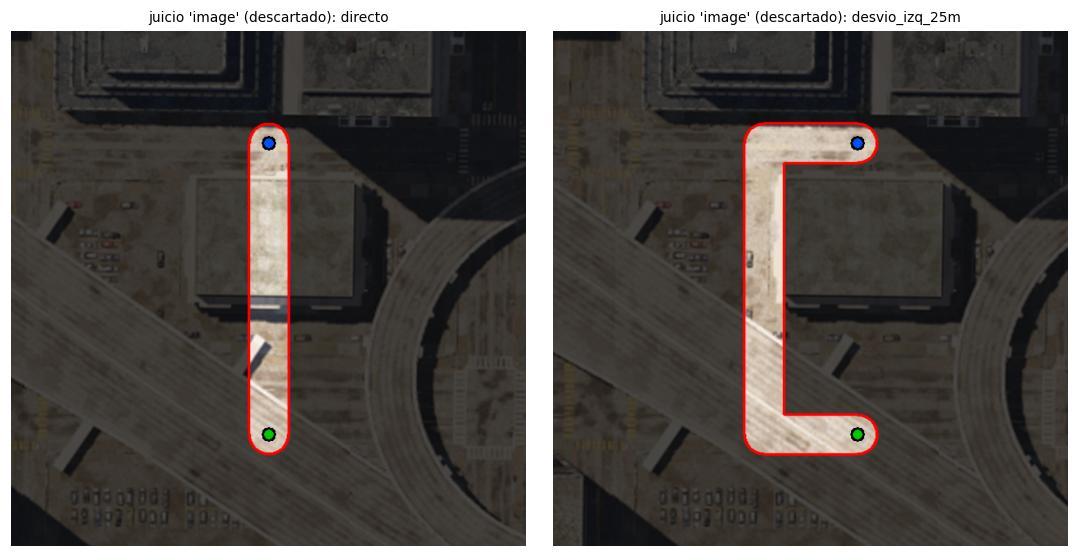

prompt de sistema (image/corridor): You see a top-down city map. The bright strip outlined in red is a drone path from the green dot (bottom) to the blue dot; the rest is darkened. Answer yes only if the whole strip covers street or open ground, with no building, trees or elevated road inside it. Reply with JSON only.


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for axi, nombre in zip(ax, ('directo', 'desvio_izq_25m')):
    c = next(c for c in cands if c['name'] == nombre)
    axi.imshow(cv2.cvtColor(RP.render_corridor(mv, c['points']), cv2.COLOR_BGR2RGB)); axi.axis('off')
    axi.set_title(f"juicio 'image' (descartado): {nombre}", fontsize=9)
plt.tight_layout(); plt.show()
print('prompt de sistema (image/corridor):', RP._PROMPTS['corridor'][0])

candidata 'directo': 77.9 m -> 10 parches cada 8.0 m


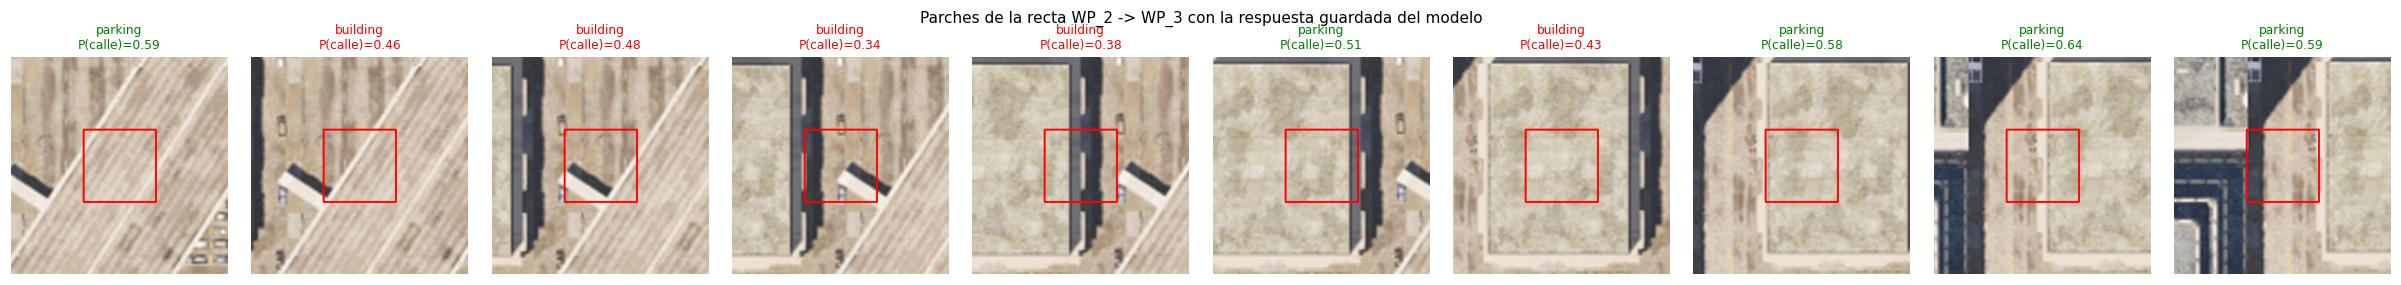

sistema: You see a top-down city map. Reply with JSON only.
usuario: What is inside the red square? street, building, trees, parking or elevated road.
esquema (decodificacion restringida): {"type": "object", "properties": {"answer": {"type": "string", "enum": ["street", "building", "trees", "parking", "elevated road"]}}, "required": ["answer"], "additionalProperties": false}


In [7]:
c_dir = next(c for c in cands if c['name'] == 'directo')
pp = RP.patch_points(c_dir['points'])
print(f"candidata 'directo': {c_dir['length_m']} m -> {len(pp)} parches cada {RP.ROUTE_PATCH_STEP_M} m")
guard = next(l for l in plan['legs'] if l['to'] == b['label'])
pat_dir = next(c for c in guard['candidates'] if c['name'] == 'directo')['patches']
fig, axs = plt.subplots(1, len(pp), figsize=(2.2 * len(pp), 2.6))
for axi, (x, y), pr in zip(np.atleast_1d(axs), pp, pat_dir):
    axi.imshow(cv2.cvtColor(RP.patch_crop(mv, x, y), cv2.COLOR_BGR2RGB)); axi.axis('off')
    axi.set_title(f"{pr['answer']}\nP(calle)={pr['p_ground']:.2f}", fontsize=8, color='green' if pr['p_ground'] >= .5 else 'red')
fig.suptitle("Parches de la recta WP_2 -> WP_3 con la respuesta guardada del modelo", fontsize=10)
plt.tight_layout(); plt.show()
print('sistema:', RP.PATCH_SYSTEM); print('usuario:', RP.PATCH_PROMPT)
print('esquema (decodificacion restringida):', json.dumps(RP.RESPONSE_JSON_SCHEMA_PATCH['json_schema']['schema']))

## §5 — De los *logprobs* a una probabilidad de «calle»

Cada consulta va con **decodificación restringida**: el servidor obliga a que la salida cumpla el esquema JSON, así que la respuesta es siempre `{"answer": "<una de las cinco clases>"}`, con temperatura 0. Además se piden `top_logprobs`, las alternativas que el modelo consideraba en cada token **antes** de aplicar la gramática.

`choice_probs_at()` toma el token que cubre el primer carácter del valor de `answer` y asigna cada alternativa a la clase cuyo nombre empieza con ese fragmento; por eso las clases tienen iniciales distintas. Normaliza la masa y devuelve la probabilidad de cada clase. La puntuación de un parche es $P(\text{calle}) = P(\text{street}) + P(\text{parking})$. Ejemplo con *tokens* construidos a mano:

In [8]:
texto = '{"answer": "parking"}'
tokens = [{'token': '{"', 'logprob': 0.0, 'top_logprobs': []},
          {'token': 'answer', 'logprob': 0.0, 'top_logprobs': []},
          {'token': '":', 'logprob': 0.0, 'top_logprobs': []},
          {'token': ' "', 'logprob': 0.0, 'top_logprobs': []},
          {'token': 'park', 'logprob': math.log(0.46),
           'top_logprobs': [{'token': 'park', 'logprob': math.log(0.46)}, {'token': 'build', 'logprob': math.log(0.31)},
                            {'token': 'street', 'logprob': math.log(0.12)}, {'token': 'tre', 'logprob': math.log(0.06)},
                            {'token': 'ele', 'logprob': math.log(0.03)}, {'token': '{', 'logprob': math.log(0.02)}]},
          {'token': 'ing"}', 'logprob': 0.0, 'top_logprobs': []}]
off = value_offsets(texto, 'answer')[0]
probs = choice_probs_at(tokens, off, RP.PATCH_CLASSES)
print('offset del valor:', off, '->', repr(texto[off:]))
display(pd.Series(probs).round(3).to_frame('P(clase)'))
print('read_patch():', RP.read_patch({'text': texto, 'tokens': tokens}))

offset del valor: 12 -> 'parking"}'


,P(clase)
street,0.122
building,0.316
trees,0.061
parking,0.469
elevated road,0.031


read_patch(): {'answer': 'parking', 'p_ground': 0.5918}


La alternativa `{` no corresponde a ninguna clase y no suma masa: la normalización se hace sobre las cinco clases. Con las respuestas guardadas del plan se ve cómo se reparten las clases y la probabilidad de calle en todos los parches del lote 6:

404 parches distintos consultados (el plan cachea por posicion: tramos y candidatas comparten puntos)


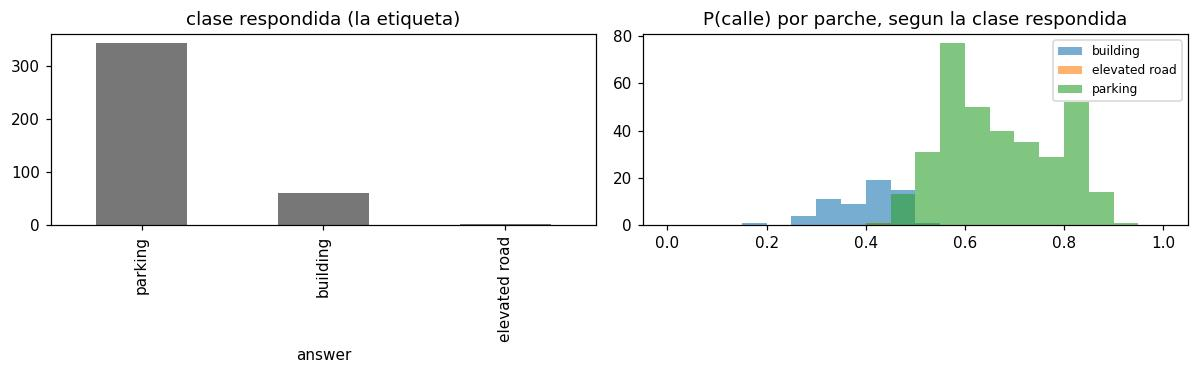

In [9]:
todos = {}
for l in plan['legs']:
    for c in l['candidates']:
        for p in c.get('patches', []):
            todos[(p['x'], p['y'])] = p
pat = pd.DataFrame(todos.values())
print(f'{len(pat)} parches distintos consultados (el plan cachea por posicion: tramos y candidatas comparten puntos)')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
pat['answer'].value_counts().plot.bar(ax=ax[0], color='#777'); ax[0].set_title('clase respondida (la etiqueta)')
for cl, g in pat.groupby('answer'):
    ax[1].hist(g['p_ground'], bins=20, range=(0, 1), alpha=0.6, label=cl)
ax[1].set_title('P(calle) por parche, segun la clase respondida'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

La etiqueta que devuelve el modelo está muy sesgada hacia una o dos clases, pero la probabilidad sí varía entre parches. Por eso el planificador **no usa la respuesta**: compara las candidatas de un tramo por su P(calle) media. En la prueba de parches etiquetados con la profundidad (NB5 §4), la respuesta tiene exactitud balanceada 0.65 y la probabilidad, AUC 0.79.

## §6 — Puntuación de las candidatas y elección

Puntaje de una candidata = P(calle) media de sus parches. `choose()` toma la de mayor puntaje y, entre las que están a menos de `ROUTE_TIE_EPS` = 0.05 de la mejor, la más corta (si empata, la recta). No hay umbral absoluto, porque las candidatas se comparan entre sí. A continuación se recalcula la elección de cada tramo **desde las respuestas guardadas por parche** y se compara con la que quedó en el plan.

In [10]:
filas, todas_ok = [], True
for li, l in enumerate(plan['legs']):
    cs = copy.deepcopy(l['candidates'])
    for c in cs:
        ps = [p['p_ground'] for p in c['patches'] if p['p_ground'] is not None]
        c['p_si'] = round(sum(ps) / len(ps), 4)
    best, motivo = RP.choose(cs)
    todas_ok &= best['name'] == l['chosen']
    top = max(c['p_si'] for c in cs)
    for c in cs:
        filas.append({'tramo': f"{l['from']} -> {l['to']}", 'candidata': c['name'], 'longitud (m)': c['length_m'],
                      'parches': len(c['patches']), 'P(calle) media': c['p_si'], 'P(calle) minima': c['p_min'],
                      'dentro de 0.05 de la mejor': c['p_si'] >= top - RP.ROUTE_TIE_EPS,
                      'elegida (recalculo)': c['name'] == best['name'], 'elegida (plan.json)': c['name'] == l['chosen']})
tab = pd.DataFrame(filas)
print('la eleccion recalculada coincide con plan.json en todos los tramos:', todas_ok)
display(tab[tab['tramo'].str.endswith('WP_3')])
display(tab[tab['elegida (recalculo)']][['tramo', 'candidata', 'longitud (m)', 'P(calle) media']])

la eleccion recalculada coincide con plan.json en todos los tramos: True


,tramo,candidata,longitud (m),parches,P(calle) media,P(calle) minima,dentro de 0.05 de la mejor,elegida (recalculo),elegida (plan.json)
17,WP_2 -> WP_3,directo,77.9,10,0.4989,0.3439,False,False,False
18,WP_2 -> WP_3,desvio_izq_25m,127.9,16,0.6304,0.5118,True,True,True
19,WP_2 -> WP_3,desvio_der_25m,127.9,16,0.5349,0.4398,False,False,False
20,WP_2 -> WP_3,desvio_izq_50m,177.9,22,0.6469,0.5201,True,False,False
21,WP_2 -> WP_3,desvio_der_50m,177.9,22,0.5761,0.4598,False,False,False


,tramo,candidata,longitud (m),P(calle) media
0,START -> WP_0_SUR,directo,51.1,0.6623
6,WP_0_SUR -> WP_1,L_norte_sur_primero,50.3,0.7842
14,WP_1 -> WP_2,desvio_der_25m,92.8,0.7460
18,WP_2 -> WP_3,desvio_izq_25m,127.9,0.6304
22,WP_3 -> WP_4,directo,42.8,0.6391
29,WP_4 -> WP_5,directo,42.8,0.7270
37,WP_5 -> WP_6,desvio_izq_50m,166.4,0.6934
39,WP_6 -> WP_7,directo,30.4,0.6772


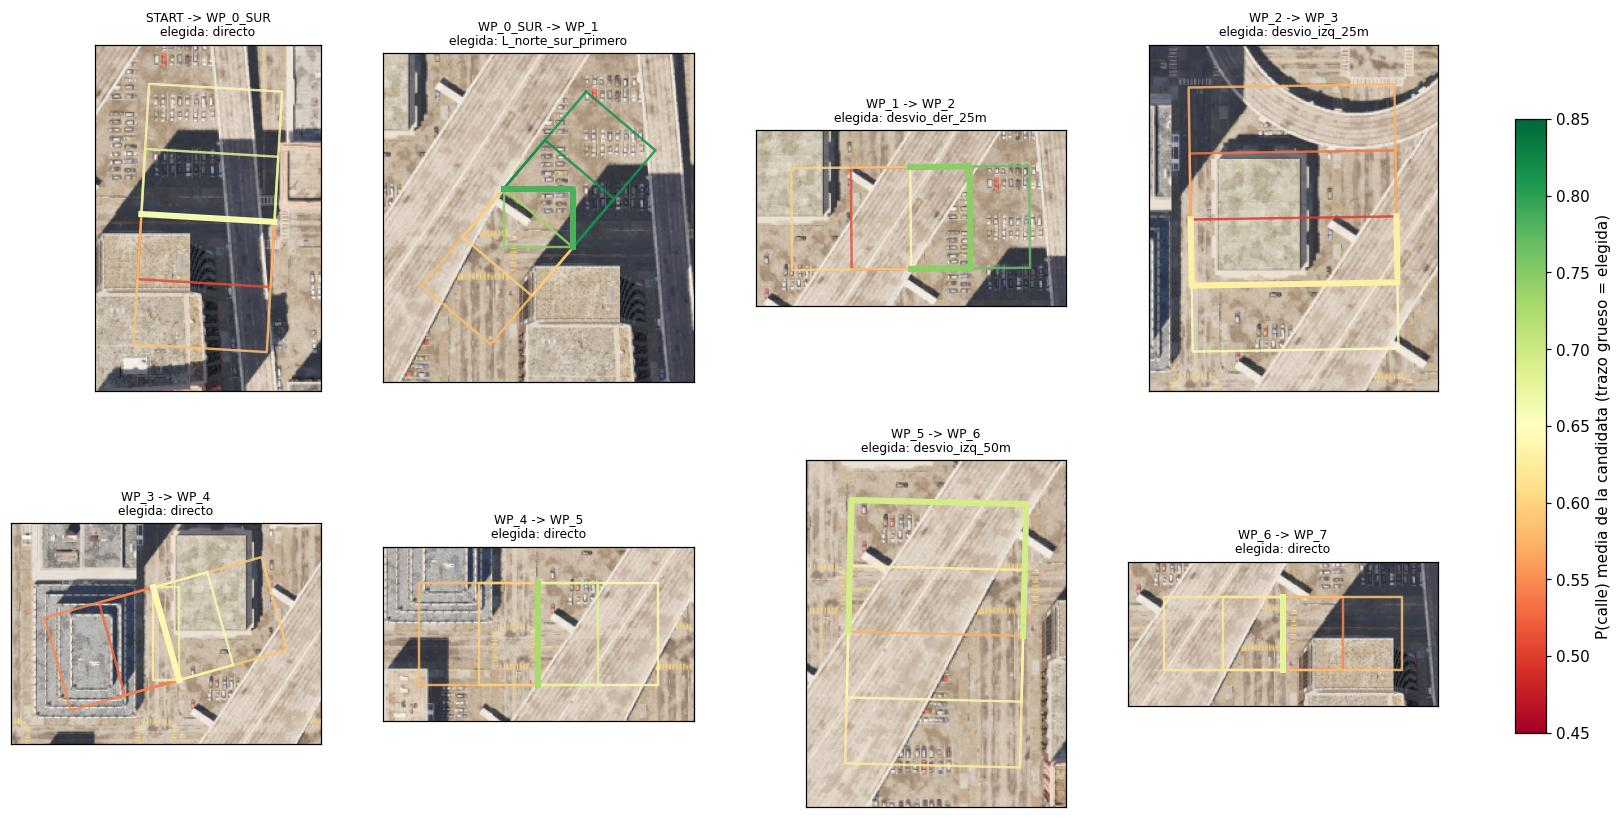

In [11]:
fig, axs = plt.subplots(2, 4, figsize=(18, 9))
for axi, l in zip(axs.flat, plan['legs']):
    cs = l['candidates']
    xs_ = [p[0] for c in cs for p in c['points']]; ys_ = [p[1] for c in cs for p in c['points']]
    img, ext = recorte(xs_, ys_, 15)
    axi.imshow(img, extent=ext)
    norm = plt.Normalize(0.45, 0.85)
    for c in sorted(cs, key=lambda c: c['p_si']):
        xs, ys = pts_xy(c['points'])
        el = c['name'] == l['chosen']
        axi.plot(ys, xs, '-', lw=4 if el else 1.6, color=plt.cm.RdYlGn(norm(c['p_si'])), alpha=1 if el else .85, zorder=3 if el else 2)
    axi.set_title(f"{l['from']} -> {l['to']}\nelegida: {l['chosen']}", fontsize=8); axi.set_xticks([]); axi.set_yticks([])
sm = plt.cm.ScalarMappable(cmap='RdYlGn', norm=plt.Normalize(0.45, 0.85))
fig.colorbar(sm, ax=axs, fraction=0.02, label='P(calle) media de la candidata (trazo grueso = elegida)')
plt.show()

## §7 — El manifiesto planificado

Los vértices intermedios de cada candidata elegida se insertan como waypoints `VIA_<WP>_<k>` (con `planned_via: true` y la altura del waypoint de destino) delante del waypoint del tramo. El plan se **cachea por contenido**: la clave combina waypoints, mapa, modelo, *prompts*, parámetros de los parches y versión del planificador. Así, todas las semillas y celdas de un lote vuelan el mismo plan, y cada `summary.json` registra con qué plan voló.

clave guardada: ad4dd01a2281 | clave recalculada con la configuracion actual: ad4dd01a2281
route_plan en el manifiesto planificado: {'mode': 'vlm', 'judge': 'patches', 'key': 'ad4dd01a2281', 'model': 'lfm2.5-vl-1.6b:q4km-ctx8k', 'map': 'citysim_ortho.png', 'vias': 7, 'legs_rerouted': 4}


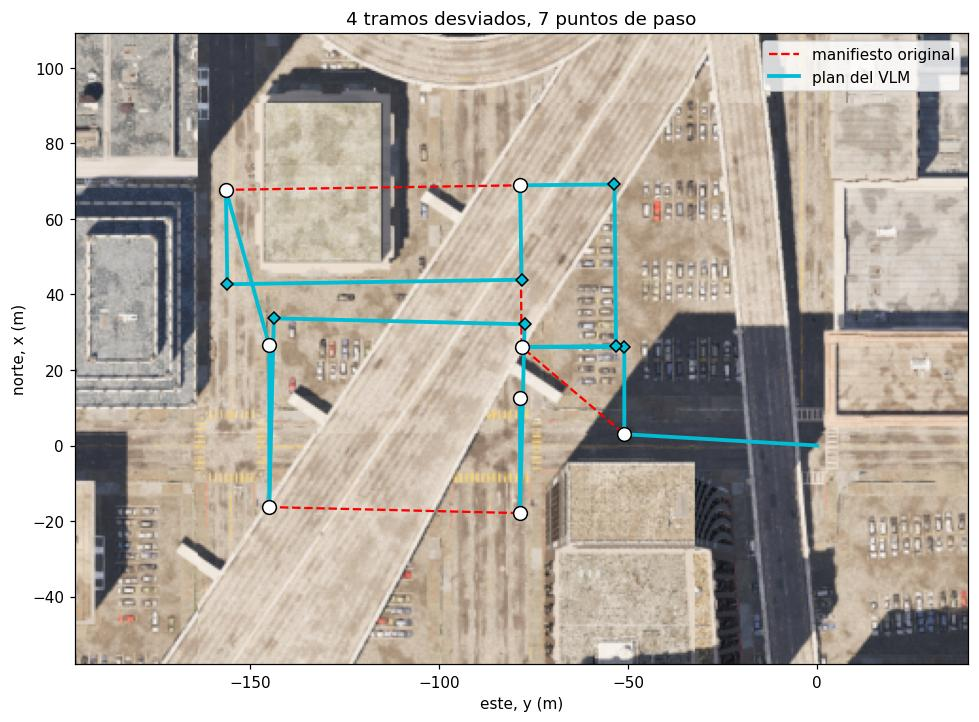

,label,x,y,z,VIA
0,WP_0_SUR,3.00,-51.00,-10.0,False
1,VIA_WP_1_1,26.10,-51.00,-10.0,True
2,WP_1,26.10,-78.20,-10.0,False
3,VIA_WP_2_1,26.33,-53.20,-10.0,True
4,VIA_WP_2_2,69.13,-53.60,-10.0,True
5,WP_2,68.90,-78.60,-10.0,False
6,VIA_WP_3_1,43.90,-78.21,-10.0,True
7,VIA_WP_3_2,42.70,-156.11,-10.0,True
8,WP_3,67.70,-156.50,-10.0,False
9,WP_4,26.50,-145.00,-10.0,False


In [12]:
print('clave guardada:', plan['key'], '| clave recalculada con la configuracion actual:', RP.plan_key(manifest))
print('route_plan en el manifiesto planificado:', planned['route_plan'])
img, ext = recorte([w['x'] for w in seq] + [w['x'] for w in planned['waypoints']], [w['y'] for w in seq] + [w['y'] for w in planned['waypoints']], 40)
fig, ax = plt.subplots(figsize=(9, 8))
ax.imshow(img, extent=ext)
ax.plot([w['y'] for w in seq], [w['x'] for w in seq], 'r--', lw=1.5, label='manifiesto original')
pl = [seq[0]] + planned['waypoints']
ax.plot([w['y'] for w in pl], [w['x'] for w in pl], '-', color='#00bcd4', lw=2.5, label='plan del VLM')
for w in planned['waypoints']:
    ax.plot(w['y'], w['x'], 'D' if w.get('planned_via') else 'o', ms=6 if w.get('planned_via') else 9,
            mfc='#00bcd4' if w.get('planned_via') else 'white', mec='k')
ax.legend(); ax.set_xlabel('este, y (m)'); ax.set_ylabel('norte, x (m)')
ax.set_title(f"{planned['route_plan']['legs_rerouted']} tramos desviados, {planned['route_plan']['vias']} puntos de paso")
plt.tight_layout(); plt.show()
display(pd.DataFrame(planned['waypoints'])[['label', 'x', 'y', 'z']].assign(VIA=[bool(w.get('planned_via')) for w in planned['waypoints']]))

In [13]:
# Consulta real (opcional): clasifica con el modelo un parche de la recta WP_2 -> WP_3 y la compara con la guardada.
if CONSULTA_EN_VIVO:
    x, y = pp[len(pp) // 2]
    r = RP.read_patch(RP.default_patch_query(RP.patch_crop(mv, x, y)))
    g = pat_dir[len(pp) // 2]
    print(f'en vivo: {r} | guardada: answer={g["answer"]}, p_ground={g["p_ground"]}')
else:
    print('CONSULTA_EN_VIVO = False: se usan las respuestas guardadas en plan.json (poner True con Ollama en', os.getenv('LOCAL_LLM_URL'), ')')

CONSULTA_EN_VIVO = False: se usan las respuestas guardadas en plan.json (poner True con Ollama en http://127.0.0.1:11434/v1 )


## §8 — ¿Funciona? El plan contra la geometría del simulador

`route_bench.py` (banco v2) etiquetó cada candidata de 11 tramos (`citysim_pilot` y `citysim_clear`) recorriéndola en AirSim cada 4 m a la altura de vuelo. La candidata es **libre** si en ningún punto hay un obstáculo a menos de 6 m en la ventana central de la profundidad. Con esa etiqueta de referencia se mide si el puntaje del planificador separa rutas libres de bloqueadas (AUC) y si la elegida es realmente libre.

59 candidatas en 11 tramos; libres 28; AUC de P(calle) media = 0.81


,mision,tramo,elegida,elegida libre,recta libre,alguna libre
0,citysim_clear,00_WP_1->WP_2,directo,True,True,True
1,citysim_clear,01_WP_2->WP_3,directo,True,True,True
2,citysim_clear,02_WP_3->WP_4,desvio_der_25m,False,True,True
3,citysim_pilot,00_START->WP_0_SUR,directo,True,True,True
4,citysim_pilot,01_WP_0_SUR->WP_1,L_norte_sur_primero,True,True,True
5,citysim_pilot,02_WP_1->WP_2,desvio_der_25m,True,True,True
6,citysim_pilot,03_WP_2->WP_3,desvio_izq_25m,True,False,True
7,citysim_pilot,04_WP_3->WP_4,directo,True,True,True
8,citysim_pilot,05_WP_4->WP_5,directo,True,True,True
9,citysim_pilot,06_WP_5->WP_6,desvio_izq_50m,True,True,True


elegida libre en 10 de 11 tramos; recta libre en 10 de 11


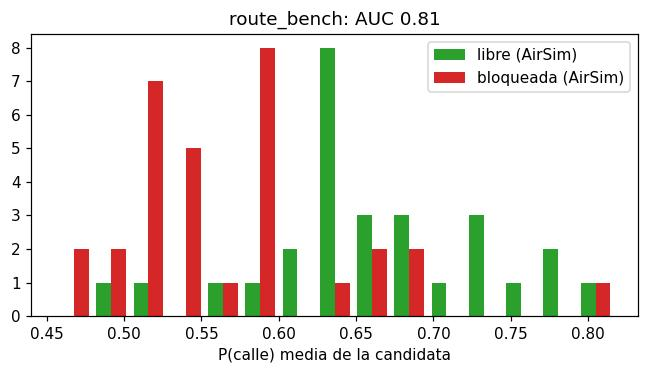

In [14]:
rb = pd.DataFrame([json.loads(l) for l in open(BENCH / 'routes.jsonl', encoding='utf-8')])
rb = rb[rb['p_si'].notna()]
pos_, neg_ = rb.loc[rb['clear'], 'p_si'].to_numpy(), rb.loc[~rb['clear'], 'p_si'].to_numpy()
auc = (np.sign(pos_[:, None] - neg_[None, :]).mean() + 1) / 2
print(f'{len(rb)} candidatas en {rb.groupby(["mission", "leg"]).ngroups} tramos; libres {rb["clear"].sum()}; AUC de P(calle) media = {auc:.2f}')
filas = []
for (m, leg), g in rb.groupby(['mission', 'leg']):
    cs = g.to_dict('records')
    best, _ = RP.choose(cs)
    filas.append({'mision': m, 'tramo': leg, 'elegida': best['candidate'], 'elegida libre': best['clear'],
                  'recta libre': bool(g.loc[g['candidate'] == 'directo', 'clear'].iloc[0]), 'alguna libre': bool(g['clear'].any())})
t8 = pd.DataFrame(filas)
display(t8)
print(f"elegida libre en {t8['elegida libre'].sum()} de {len(t8)} tramos; recta libre en {t8['recta libre'].sum()} de {len(t8)}")
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist([pos_, neg_], bins=15, label=['libre (AirSim)', 'bloqueada (AirSim)'], color=['#2ca02c', '#d62728'])
ax.set_xlabel('P(calle) media de la candidata'); ax.legend(); ax.set_title(f'route_bench: AUC {auc:.2f}')
plt.tight_layout(); plt.show()

**Lectura (informe §11.0).**

- **Separación.** El puntaje separa rutas libres de bloqueadas (AUC ≈ 0.8).
- **Elección.** En el único tramo con la recta bloqueada (`citysim_pilot` WP_2 → WP_3) el plan elige un desvío libre. En un tramo de `citysim_clear` elige un desvío bloqueado con la recta libre. Por eso el plan se activa solo en los escenarios con obstrucción: los `*_clear` vuelan el manifiesto tal cual.
- **Alcance.** Es la única tarea del sistema en la que el VLM aporta una señal medible.

## §9 — Capa estratégica: sub-metas ancladas a la pose

La capa estratégica es el lazo lento en vuelo. Mira **un** fotograma, lo divide en una grilla de 3×3 sobre un recorte cuadrado central y pregunta qué sectores están libres a 15 m. La respuesta se traduce a una sub-meta en **coordenadas del mundo**, calculada con la pose del instante de captura. La sub-meta sigue siendo correcta aunque el dron haya girado y avanzado mientras la fuente respondía. Con el VLM eso eran 0.9 s; con la profundidad, unos 0.13 s.

**Geometría.** Con el recorte cuadrado, los sectores laterales y los verticales quedan a la misma distancia angular del eje óptico (±24°, con el campo de 90° sobre 1080 px). Sobre el fotograma completo, los laterales quedaban a 33.7° y un rodeo por arriba ganaba siempre por la forma del cuadro.

In [15]:
side, f = 720, VS._focal_px(1080)
cc = VS.cell_centers_deg(side, f)
print(f'recorte {side}x{side} px, focal {f:.0f} px, semicampo del recorte {VS.crop_half_fov_deg(side, f):.1f} deg')
display(pd.DataFrame(cc, index=['azimut (deg)', 'elevacion (deg)']).round(1))
print('\nprompt de sistema con fuente VLM:\n', VS.SYSTEM_PROMPT_STRATEGIC)
print('\nmensaje de una consulta:', VS.strategic_prompt('WP_3', 42.0, None, -31.0, 10.0))

recorte 720x720 px, focal 540 px, semicampo del recorte 33.7 deg


,A1,A2,A3,B1,B2,B3,C1,C2,C3
azimut (deg),-24.0,-24.0,-24.0,0.0,0.0,0.0,24.0,24.0,24.0
elevacion (deg),24.0,0.0,-24.0,24.0,0.0,-24.0,24.0,0.0,-24.0



prompt de sistema con fuente VLM:
 You see the front camera of a drone flying low in a city, split into a 3x3 grid: columns A B C (left to right), rows 1 2 3 (top, drone height, bottom). The red GOAL mark is the destination.
For each cell: "free" if the drone can fly 15 m that way, "blocked" if a building, wall, tree, bridge or roof is closer than 15 m. Reply with JSON only.

mensaje de una consulta: Goal WP_3: 42 m, outside the image, 31 deg to the left (GOAL mark on the edge). Altitude 10 m.


**`decide_subgoal()`**, con la respuesta ya normalizada a `libre` / `bloqueado` por sector:

1. Si el sector donde cae la meta está libre: `directo_libre`. El guiado directo alcanza y no hay sub-meta.
2. Si no, se toman los sectores libres más cercanos a la dirección de la meta, a menos de `VLM_SUBGOAL_TIE_DEG` = 10° del mejor. Entre ellos gana la fila del medio, luego la de arriba y por último la de abajo (el suelo está abajo).
3. La sub-meta queda a $d = \min(15\text{ m},\ d_{WP})$ en el rumbo absoluto $\psi_\text{captura} + az$, con un cambio de altura $d\tan(el)$ acotado a ±4 m y nunca por debajo de 6 m.
4. Se descarta si venció (más de 10 s), si cambió el waypoint real o si el dron ya la pasó.

Se reproduce una sub-meta real de la corrida de referencia: con el ancla registrada y la respuesta registrada, se recalcula el punto y se compara con el que se inyectó en vuelo.

In [16]:
RUN = next((V4 / 'lote6_citysim_pilot' / ESC / 'slm' / 'depth').glob('seed_233_*'))
recs = [json.loads(l) for l in open(RUN / f'{RUN.name}.jsonl', encoding='utf-8')]
por_ts = {round(float(r['state']['telemetry'].get('timestamp') or 0), 3): r for r in recs if r['state'].get('telemetry')}
filas = []
vistos = set()
for r in recs:
    v = r['state'].get('_vlm_strategic') or {}
    if v.get('outcome') != 'subgoal' or v['anchor']['ts'] in vistos:
        continue
    vistos.add(v['anchor']['ts'])
    rc = por_ts.get(round(v['anchor']['ts'], 3))
    if rc is None:
        continue
    st = rc['state']
    pos = st['telemetry']['position']
    wp = next(w for w in st['waypoints'] if w['label'] == v['anchor']['wp_label'])
    dist = math.hypot(wp['x'] - pos['x'], wp['y'] - pos['y'])
    yaw = math.degrees(st['telemetry']['orientation']['yaw'])
    goal_az = VS._norm_deg(VS.bearing_to(pos, wp) - yaw)
    goal_el = math.degrees(math.atan2(pos['z'] - wp.get('z', -10.0), max(dist, 1e-3)))
    half = VS.crop_half_fov_deg(side, f)
    in_view = abs(goal_az) <= min(VS.VLM_STRATEGIC_MAX_GOAL_OFF_DEG, half) and abs(goal_el) <= half
    anchor = {'x': pos['x'], 'y': pos['y'], 'z': pos['z'], 'yaw_deg': yaw, 'sent_at': 0.0, 'goal_az_deg': goal_az,
              'goal_el_deg': goal_el, 'goal_cell': VS.cell_for_direction(goal_az, goal_el, side, f) if in_view else None,
              'crop_side': side, 'focal_px': f, 'wp_label': wp['label'], 'wp_dist_xy': dist}
    estado_ahora = {'waypoints': st['waypoints'], 'current_wp_index': st['current_wp_index'], 'telemetry': st['telemetry']}
    sub, motivo = VS.decide_subgoal(v['parsed'], anchor, estado_ahora, now=0.0)
    filas.append({'ts': v['anchor']['ts'], 'meta': wp['label'], 'az meta (deg)': round(goal_az, 1), 'sector (vuelo)': v['subgoal']['sector'],
                  'sector (recalculo)': None if sub is None else sub['sector'],
                  'x,y vuelo': (v['subgoal']['x'], v['subgoal']['y']), 'x,y recalculo': None if sub is None else (sub['x'], sub['y']),
                  'motivo': motivo})
sg = pd.DataFrame(filas)
sg['coincide'] = [a == b for a, b in zip(sg['x,y vuelo'], sg['x,y recalculo'])]
print(f"sub-metas reproducidas: {len(sg)}; coinciden exactamente: {sg['coincide'].sum()} ({sg['coincide'].mean():.0%})")
display(sg.head(8))

sub-metas reproducidas: 77; coinciden exactamente: 77 (100%)


,ts,meta,az meta (deg),sector (vuelo),sector (recalculo),"x,y vuelo","x,y recalculo",motivo,coincide
0,1.793108e+09,VIA_WP_1_1,38.2,C2,C2,"(20.11, -54.91)","(20.11, -54.91)","sector C2 (+24 deg, +0 deg, 15 m)",True
1,1.793108e+09,WP_1,57.1,C2,C2,"(18.63, -62.26)","(18.63, -62.26)","sector C2 (+24 deg, +0 deg, 15 m)",True
2,1.793108e+09,WP_1,7.3,C2,C2,"(28.44, -73.94)","(28.44, -73.94)","sector C2 (+24 deg, +0 deg, 15 m)",True
3,1.793108e+09,WP_1,9.1,B1,B1,"(24.37, -79.25)","(24.37, -79.25)","sector B1 (+0 deg, +24 deg, 13 m)",True
4,1.793108e+09,WP_1,5.3,B1,B1,"(25.29, -78.76)","(25.29, -78.76)","sector B1 (+0 deg, +24 deg, 11 m)",True
5,1.793108e+09,VIA_WP_2_1,59.6,C2,C2,"(33.77, -66.49)","(33.77, -66.49)","sector C2 (+24 deg, +0 deg, 15 m)",True
6,1.793108e+09,VIA_WP_2_2,-47.9,A2,A2,"(37.67, -48.22)","(37.67, -48.22)","sector A2 (-24 deg, +0 deg, 15 m)",True
7,1.793108e+09,VIA_WP_2_2,32.6,C1,C1,"(53.38, -53.75)","(53.38, -53.75)","sector C1 (+24 deg, +24 deg, 15 m)",True


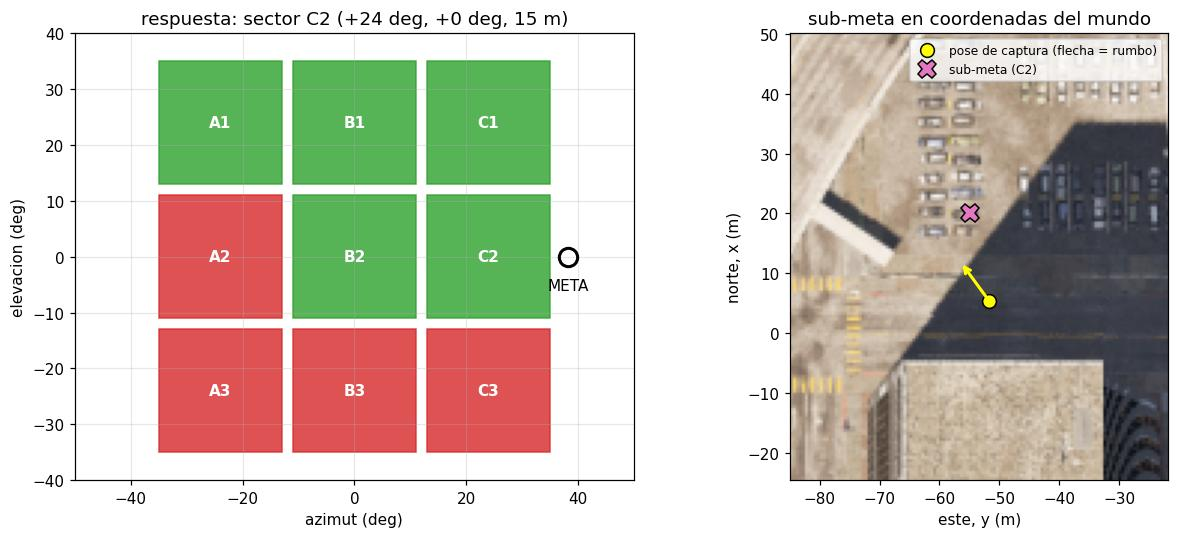

In [17]:
r0 = sg[sg['coincide']].iloc[0]
rec = next(r for r in recs if (r['state'].get('_vlm_strategic') or {}).get('anchor', {}).get('ts') == r0['ts'])
v = rec['state']['_vlm_strategic']
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
estado_celdas = v['parsed']['sectores']
for k, (az, el) in cc.items():
    ax[0].add_patch(mpatches.Rectangle((az - 11, el - 11), 22, 22, color='#2ca02c' if estado_celdas[k] == 'libre' else '#d62728', alpha=.8))
    ax[0].text(az, el, k, ha='center', va='center', color='w', weight='bold')
ax[0].plot(r0['az meta (deg)'], 0, 'o', ms=12, mfc='none', mec='k', mew=2); ax[0].text(r0['az meta (deg)'], -6, 'META', ha='center')
ax[0].set_xlim(-50, 50); ax[0].set_ylim(-40, 40); ax[0].set_aspect('equal'); ax[0].grid(alpha=.3)
ax[0].set_xlabel('azimut (deg)'); ax[0].set_ylabel('elevacion (deg)'); ax[0].set_title(f"respuesta: {v['reason']}")
a_ = v['anchor']; s_ = v['subgoal']
img, ext = recorte([a_['x'], s_['x']], [a_['y'], s_['y']], 30)
ax[1].imshow(img, extent=ext)
ax[1].annotate('', xy=(a_['y'] + 8 * math.sin(math.radians(a_['yaw_deg'])), a_['x'] + 8 * math.cos(math.radians(a_['yaw_deg']))),
               xytext=(a_['y'], a_['x']), arrowprops=dict(arrowstyle='->', color='yellow', lw=2))
ax[1].plot(a_['y'], a_['x'], 'o', mfc='yellow', mec='k', ms=9, label='pose de captura (flecha = rumbo)')
ax[1].plot(s_['y'], s_['x'], 'X', mfc='#e377c2', mec='k', ms=12, label=f"sub-meta ({s_['sector']})")
ax[1].legend(fontsize=8); ax[1].set_title('sub-meta en coordenadas del mundo'); ax[1].set_xlabel('este, y (m)'); ax[1].set_ylabel('norte, x (m)')
plt.tight_layout(); plt.show()

**Observación sobre la fila de abajo.** Con la profundidad como fuente, en la corrida de referencia los sectores de la fila 3 salen bloqueados en el 100 % de las consultas (NB2 §6), y la geometría lo explica. A 10 m de altura, el borde inferior del recorte mira 33.7° hacia abajo y corta el suelo a $10/\tan(33.7°) \approx 15$ m. El percentil 5 del sector (lo más cercano) queda entonces por debajo de los 15 m de «libre». Con el VLM pasaba lo contrario: el banco mostró que respondía «libre» en las filas 1 y 3 siempre, sin mirar la escena. La regla de desempate por fila (`_ROW_PREF`) y el margen `VLM_SUBGOAL_TIE_DEG` se agregaron por ese motivo (comentario del 2026-10-07 en `vlm_strategic.py`).

In [18]:
for alt in (8, 10, 15, 20):
    borde = VS.crop_half_fov_deg(side, f)
    print(f'altura {alt:>2} m: el borde inferior del recorte ({-borde:.1f} deg) corta el suelo a {alt / math.tan(math.radians(borde)):.1f} m; '
          f'el centro de la fila 3 ({cc["B3"][1]:.1f} deg) a {alt / math.tan(math.radians(-cc["B3"][1])):.1f} m')

altura  8 m: el borde inferior del recorte (-33.7 deg) corta el suelo a 12.0 m; el centro de la fila 3 (-24.0 deg) a 18.0 m
altura 10 m: el borde inferior del recorte (-33.7 deg) corta el suelo a 15.0 m; el centro de la fila 3 (-24.0 deg) a 22.5 m
altura 15 m: el borde inferior del recorte (-33.7 deg) corta el suelo a 22.5 m; el centro de la fila 3 (-24.0 deg) a 33.8 m
altura 20 m: el borde inferior del recorte (-33.7 deg) corta el suelo a 30.0 m; el centro de la fila 3 (-24.0 deg) a 45.0 m


## §10 — Barrido panorámico en deadlock

Cuando `navigate` declara un deadlock (NB3 §6, regla 2), `deep_scan_cycle()` hace un barrido:

1. Gira el dron a `SCAN_HEADING_COUNT_DEEP` rumbos y toma una imagen en cada uno.
2. Pregunta a la fuente qué rumbos son transitables. Con el VLM, imágenes numeradas y el *prompt* de abajo. Con la profundidad, el sector central B2 de cada imagen con p5 ≥ 15 m.
3. Convierte el rumbo elegido en una sub-meta con la misma función `build_subgoal()` de §9.

Los rumbos ya intentados cerca del mismo lugar se excluyen (`SCAN_FAILED_SECTOR_DEG`, `SCAN_REPEAT_RADIUS_M`). Si el barrido falla (*watchdog*, formato, rotación imposible), el escape cae a `GANAR_ALTURA`. En el banco, el VLM declaró transitables **todos** los rumbos de todos los barridos (NB5 §3). Con él, la salida del atasco la habría decidido la exclusión de rumbos ya probados, no el modelo.

In [19]:
from src.agents import deep_scan as DS
print('rumbos por barrido:', DS.SCAN_HEADING_COUNT_DEEP, '| sector excluido alrededor de un rumbo fallido:', DS.SCAN_FAILED_SECTOR_DEG, 'deg')
print('\nprompt de sistema del barrido (fuente VLM):\n', DS.SYSTEM_PROMPT_DEEP_SCAN)
sg_ = SG.build_subgoal(0.0, 0.0, -10.0, heading_deg=90.0, elevation_deg=0.0, wp_dist_xy=40.0, label='SCAN_SUBGOAL')
print('\nbuild_subgoal desde (0, 0, -10) con rumbo 90 deg (este) y WP a 40 m ->', sg_)

rumbos por barrido: 4 | sector excluido alrededor de un rumbo fallido: 45.0 deg

prompt de sistema del barrido (fuente VLM):
 You see numbered images from a drone flying low in a city; it turned in place and each image faces a different direction. For each image give:
- view: what is ahead at drone height within 15 m: open (street, square, sky), facade, wall, vegetation, inside (dark or uniform, inside a building) or unclear.
- free: true only if the drone can fly straight 15 m without hitting anything.
Reply with JSON only.

build_subgoal desde (0, 0, -10) con rumbo 90 deg (este) y WP a 40 m -> {'x': 0.0, 'y': 15.0, 'z': -10.0, 'label': 'SCAN_SUBGOAL', 'dist_m': 15.0}


## §11 — Resumen

- El VLM **planifica antes del vuelo**. Clasifica parches del mapa cenital registrado y el código elige, entre candidatas geométricas, la de mayor probabilidad media de calle. En la v4 desvía 4 de los 8 tramos de `citysim_pilot`, y en el banco la elección es libre en 10 de 11 tramos (AUC 0.81).
- En vuelo, la capa estratégica y el barrido traducen «qué sectores o rumbos están libres» a sub-metas en el marco del mundo, ancladas a la pose de captura. La fuente es la profundidad estimada: el VLM no pasó el banco (NB5), y la geometría del recorte explica el comportamiento de cada fila.